# Play with sounds from the McGill Sound Dataset

In [7]:
import numpy as np
import matplotlib.pyplot as plt

### Libraries needed

Following this thread:  https://realpython.com/playing-and-recording-sound-python/


I decided to explore `pydub` since it can read various file formats via *ffmpeg*.  

**ffmpeg**

Thus, I first had to installffmpeg. Followed: https://windowsloop.com/install-ffmpeg-windows-10/   
**NEW**

<pre>winget install ffmpeg</pre>

**Old**

* downloaded static ffmpeg libraries in zip file
* unzipped and moved to C:\Users\jhetrick\usr\ffmpeg\
* added `C:\Users\jhetrick\usr\ffmpeg\bin` to $PATH
* tested ffmpeg at the command line, by opening a DOS shell and typing ffmpeg.
</font>

**ffmpeg-python**

Next, I installed the `ffmpeg-python` API.
<pre>
pip install ffmpeg-python
</pre>

**pydub**

Finally, install pydub.
<pre>
pip install pydub
</pre>



## Read a WMA file using `pydub`

In [8]:
from pydub import AudioSegment
from pydub.playback import play

In [9]:
import os
ffmpeg_path = r"C:\Users\jhetrick\ffmpeg\ffmpeg-2026-09-14\bin"

# Update your system environment path for this session
os.environ["PATH"] += os.pathsep + ffmpeg_path

# Explicitly tell Pydub where to look
AudioSegment.converter = os.path.join(ffmpeg_path, "ffmpeg.exe")
AudioSegment.ffprobe   = os.path.join(ffmpeg_path, "ffprobe.exe")

In [5]:
sound = AudioSegment.from_mp3('soft_re.mp3')

#sound = AudioSegment.from_file('01 Track 1.wma', 'wma')

# after running:   ffmpeg -i "01 Track 1.wma" "01 Track 1.wav"

#sound = AudioSegment.from_file('../Soundbank_McGill/Soundbank_WB/flu-e4-ord-mf.aif')

play(sound)

In [8]:
sound

In [11]:
type(sound)

pydub.audio_segment.AudioSegment

In [12]:
samples = sound.get_array_of_samples()

In [13]:
type(samples)

array.array

Hard to get a *numpy* array out of a sound!



---

$$-\infty-$$

---

Trying something else.

## PySoundFile

https://pypi.org/project/PySoundFile/

**CCFI**

First I installed *CFFI* via conda, as recommended.
<pre>
conda install cffi
</pre>

**pysoundfile**

Next, use pip to install pysoundfile.
<pre>
pip install pysoundfile
</pre>


In [10]:
import soundfile as sf

data, samplerate = sf.read('soft_re.mp3')

ModuleNotFoundError: No module named 'soundfile'

Fails on MP3 file.

However it works on a WAV file.

---

## Use FFMPEG at the Windows command line: wma -> wav

I used *ffmpeg* to convert one of the McGill sound files to WAV. The command and output is:
<pre>
> ffmpeg -i "01 Track 1.wma" "01 Track 1.wav"

ffmpeg version N-94383-g3883c9d147 Copyright (c) 2000-2019 the FFmpeg developers
  built with gcc 9.1.1 (GCC) 20190716
  configuration: --enable-gpl --enable-version3 --enable-sdl2 --enable-fontconfig --enable-gnutls --enable-iconv --enable-libass --enable-libdav1d --enable-libbluray --enable-libfreetype --enable-libmp3lame --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libopus --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libtheora --enable-libtwolame --enable-libvpx --enable-libwavpack --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libzimg --enable-lzma --enable-zlib --enable-gmp --enable-libvidstab --enable-libvorbis --enable-libvo-amrwbenc --enable-libmysofa --enable-libspeex --enable-libxvid --enable-libaom --enable-libmfx --enable-amf --enable-ffnvcodec --enable-cuvid --enable-d3d11va --enable-nvenc --enable-nvdec --enable-dxva2 --enable-avisynth --enable-libopenmpt
  libavutil      56. 32.100 / 56. 32.100
  libavcodec     58. 55.100 / 58. 55.100
  libavformat    58. 30.100 / 58. 30.100
  libavdevice    58.  9.100 / 58.  9.100
  libavfilter     7. 58.100 /  7. 58.100
  libswscale      5.  6.100 /  5.  6.100
  libswresample   3.  6.100 /  3.  6.100
  libpostproc    55.  6.100 / 55.  6.100
Guessed Channel Layout for Input Stream #0.0 : stereo
Input #0, asf, from '01 Track 1.wma':
  Metadata:
    WM/Track        : 0
    track           : 1
    WM/MediaPrimaryClassID: {D1607DBC-E323-4BE2-86A1-48A42A28441E}
    WM/EncodingTime : 18446744071967571856
    WMFSDKVersion   : 12.0.17134.556
    WMFSDKNeeded    : 0.0.0.0000
    AverageLevel    : 1147
    PeakValue       : 7841
    IsVBR           : 0
    DeviceConformanceTemplate: L1
  Duration: 00:03:21.36, start: 0.000000, bitrate: 129 kb/s
    Stream #0:0: Audio: wmav2 (a[1][0][0] / 0x0161), 44100 Hz, stereo, fltp, 128 kb/s
Stream mapping:
  Stream #0:0 -> #0:0 (wmav2 (native) -> pcm_s16le (native))
Press [q] to stop, [?] for help
Output #0, wav, to '01 Track 1.wav':
  Metadata:
    WM/Track        : 0
    IPRT            : 1
    WM/MediaPrimaryClassID: {D1607DBC-E323-4BE2-86A1-48A42A28441E}
    WM/EncodingTime : 18446744071967571856
    WMFSDKVersion   : 12.0.17134.556
    WMFSDKNeeded    : 0.0.0.0000
    AverageLevel    : 1147
    PeakValue       : 7841
    IsVBR           : 0
    DeviceConformanceTemplate: L1
    ISFT            : Lavf58.30.100
    Stream #0:0: Audio: pcm_s16le ([1][0][0][0] / 0x0001), 44100 Hz, stereo, s16, 1411 kb/s
    Metadata:
      encoder         : Lavc58.55.100 pcm_s16le
size=   34696kB time=00:03:21.36 bitrate=1411.5kbits/s speed= 586x
video:0kB audio:34696kB subtitle:0kB other streams:0kB global headers:0kB muxing overhead: 0.000248%
</pre>

In [7]:
# now read this WAV file
data, samplerate = sf.read('01 Track 1.wav')


In [8]:
data.shape

(8882176, 2)

In [9]:
samplerate

44100

In [10]:
data

array([[ 0.   ,  0.   ],
       [ 0.   ,  0.   ],
       [ 0.   ,  0.   ],
       ..., 
       [-0.001, -0.001],
       [-0.001, -0.001],
       [-0.001, -0.001]])

<IPython.core.display.Javascript object>


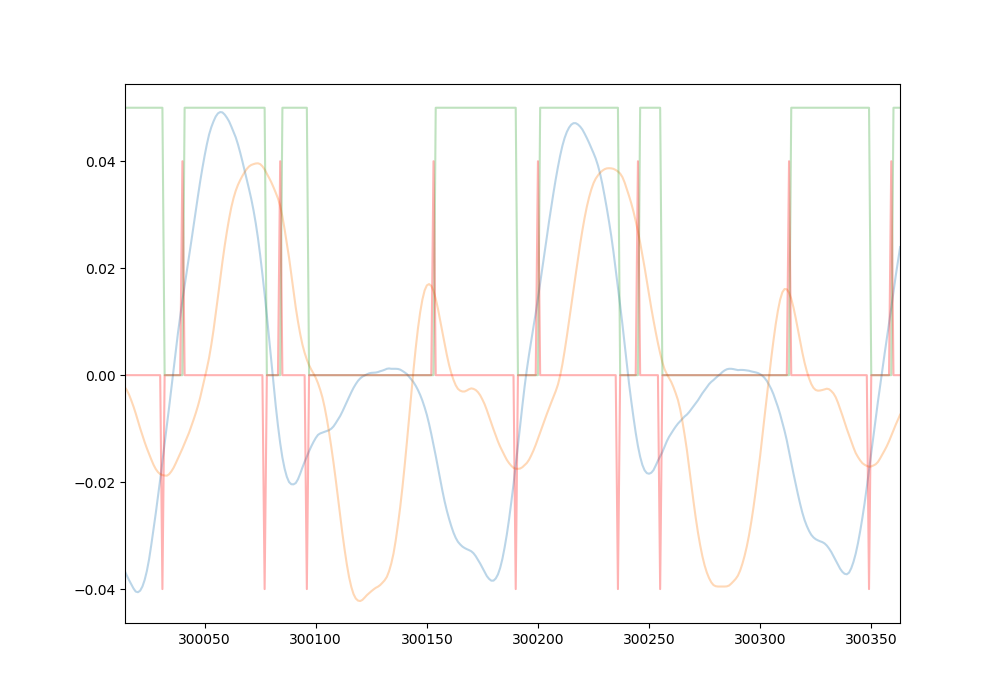

(300000, 301000)

In [41]:
%matplotlib notebook

plt.plot(range(data.shape[0]), data[:,0], alpha=0.3)
plt.plot(range(data.shape[0]), data[:,1], alpha=0.3)
plt.plot(range(data.shape[0]), mask*0.05, alpha=0.3)
plt.plot(range(data.shape[0]-1), np.diff(mask)*0.04,'r', alpha=0.3)
plt.xlim(300000,301000)


In [26]:
d = np.array([0,0,1,1,1,0,0,0,1,1,1,0,0,0,1,1,1,0])
np.diff(d)

array([ 0,  1,  0,  0, -1,  0,  0,  1,  0,  0, -1,  0,  0,  1,  0,  0, -1])

In [16]:
data

array([[ 0.   ,  0.   ],
       [ 0.   ,  0.   ],
       [ 0.   ,  0.   ],
       ..., 
       [-0.001, -0.001],
       [-0.001, -0.001],
       [-0.001, -0.001]])

In [37]:
mask = (np.abs(data[:,0]) > 0.015).astype(int)

In [42]:
srcfile = 'vln-gs7-nhf-mf.nbb'

f = np.fromfile(srcfile, dtype='float32')

In [43]:
f

array([ 0.001,  0.   ,  0.   , ...,  0.   ,  0.   ,  0.   ], dtype=float32)

In [45]:
len(f)

2048

<IPython.core.display.Javascript object>


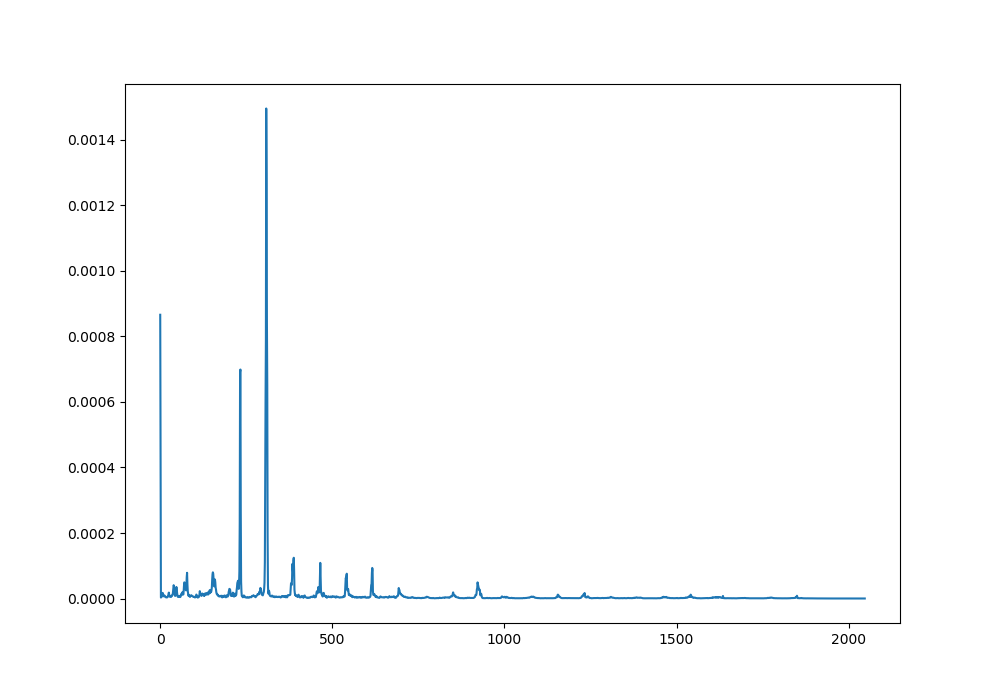

In [44]:
%matplotlib notebook

plt.plot(range(len(f)), f)

In [36]:
mask[100000:101000]

array([1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 1,

In [30]:
data[:,0]

array([-0.006, -0.006, -0.006, ..., -0.006, -0.006, -0.006])

How about the McGill wma files?

In [39]:
data, samplerate = sf.read('01 Track 1.wma', format='wma')

ValueError: Unknown format: 'wma'

In [11]:
import simpleaudio as sa

frequency = 261  # C3
fs = 44100  # 44100 samples per second
seconds = 3  # Note duration of 3 seconds

# Generate array with seconds*sample_rate steps, ranging between 0 and seconds
t = np.linspace(0, seconds, seconds * fs, False)

# Generate a 440 Hz sine wave
note = np.sin(frequency * t * 2 * np.pi)

# Ensure that highest value is in 16-bit range
audio = note * (2**15 - 1) / np.max(np.abs(note))
# Convert to 16-bit data
audio = audio.astype(np.int16)

# Start playback
play_obj = sa.play_buffer(audio, 1, 2, fs)

# Wait for playback to finish before exiting
play_obj.wait_done()

Let's create a C3 *marimba tone* (partials 1:4:10  see http://www.lafavre.us/tuning-marimba.htm )

In [12]:
frequency = 130  # Our played note will be 440 Hz
samplerate = 44100  # 44100 samples per second
seconds = 1  # Note duration of 3 seconds

# Generate array with seconds*sample_rate steps, ranging between 0 and seconds
t = np.linspace(0, seconds, seconds * samplerate, False)

# Generate a 440 Hz sine wave
note =        np.sin(     frequency * t * 2 * np.pi) + \
       0.5  * np.sin( 4 * frequency * t * 2 * np.pi) + \
       0.25 * np.sin(10 * frequency * t * 2 * np.pi)

# with envelope
#note = (np.sin(frequency * t * 2 * np.pi) + \
#       np.sin(4 * frequency * t * 2 * np.pi) + \
#       np.sin(10 * frequency * t * 2 * np.pi)) * np.exp(-10*t)

# Ensure that highest value is in 16-bit range
audio = note * (2**15 - 1) / np.max(np.abs(note))
# Convert to 16-bit data
audio = audio.astype(np.int16)

# Start playback
play_obj = sa.play_buffer(audio, 1, 2, samplerate)

# Wait for playback to finish before exiting
play_obj.wait_done()

The *note* (in time-domain)

In [441]:
note

array([ 0.   ,  0.102,  0.201, ..., -0.298, -0.201, -0.102])

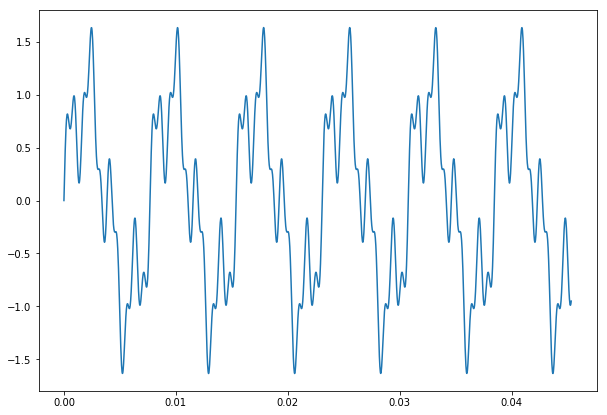

In [442]:
%matplotlib inline

def setPLTdisplay(n, m):
    plt.rcParams['figure.figsize'] = (n, m)
setPLTdisplay(10, 7)

plt.plot(t[:2000], note[:2000], '-')

---

## FFT

In [468]:
from scipy.fftpack import fft, ifft

noteFFT = fft(note)

**Real part**

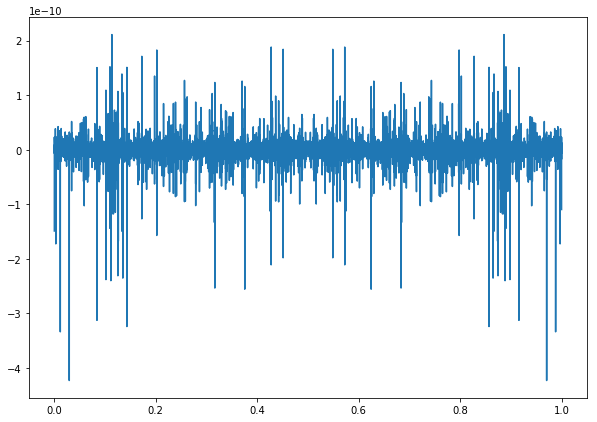

In [444]:
plt.plot(t, noteFFT.real)

Note range ($10^{-10} \sim 0$)

**Complex part**

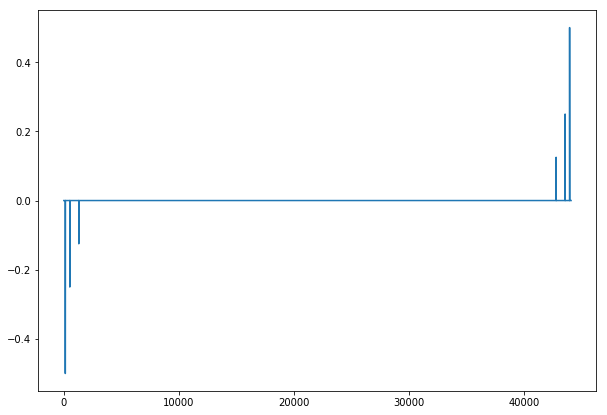

In [469]:
plt.plot(range(len(noteFFT)), noteFFT.imag/44100)

There's the 1:4:10

Also, $H(f) = H^*(-f)$ as described in NR, since note(t) is real.

In [446]:
len(noteFFT)/2

22050.0

In [470]:
halflen = int(len(noteFFT)/2)

## Power spectrum

Let N=8, then scematically, the FFT looks like this: 

<pre>
[ 0 ][ 1 ][ 2 ][ 3 ][ 4 ][ 5 ][ 6 ][ 7 ]  
zero  f1   f2   f3   f4   -f3  -f2  -f1  
                    -f4 
</pre>

N=8, halflen = 4

* `noteFFT[0]` is the zero-mode ($a_{f=0}$).
* `noteFFT[1:halflen+1]` is the +freq set
* `noteFFT[halflen+1:]` is the -freq set

Make power spectrum--assuming that the zero mode is left out, hence `power` starts from `noteFFT[1:]`

In [448]:
power = np.abs(noteFFT[1:halflen+1])

Text(0.5, 1.0, 'Power spectrum of the marimba tone')

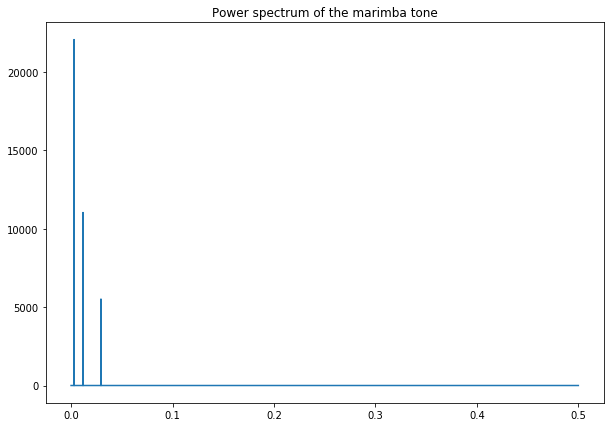

In [449]:
plt.plot(t[:halflen], power)
plt.title('Power spectrum of the marimba tone')

In [450]:
len(power)

22050

Now, from the *power spectrum*, we can reconstruct an actual FFT, then the corresponding *sound*

In [451]:
trialFFT = power * 1j

In [452]:
len(trialFFT)

22050

In [453]:
trialFFT = np.insert(trialFFT, 0, 0+0j)

In [454]:
trialFFT

array([ 0.+0.j,  0.+0.j,  0.+0.j, ...,  0.+0.j,  0.+0.j,  0.+0.j])

In [455]:
len(trialFFT)

22051

**Example** 

Get the slicing correct:

In [456]:
x = [0,1,2,3,4,5,6,7]

In [457]:
x[-2:0:-1]

[6, 5, 4, 3, 2, 1]

In [458]:
x[0:] + x[-2:0:-1]

[0, 1, 2, 3, 4, 5, 6, 7, 6, 5, 4, 3, 2, 1]

Now, use the reversed, sliced power to add the $-f$ portion of .

In [459]:
trialFFT = np.append(trialFFT, -trialFFT[-2:0:-1])

In [460]:
trialFFT

array([ 0.+0.j,  0.+0.j,  0.+0.j, ..., -0.-0.j, -0.-0.j, -0.-0.j])

In [461]:
len(trialFFT)

44100

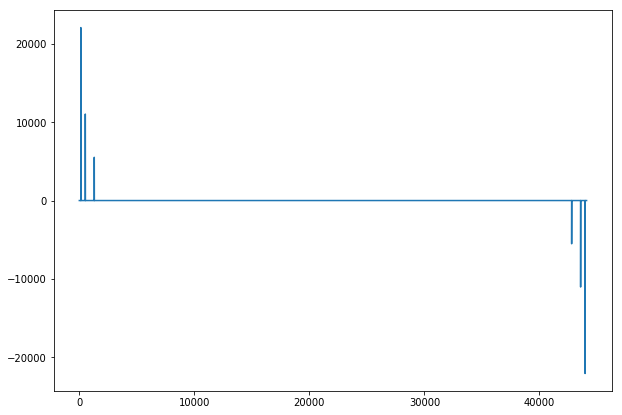

In [462]:
plt.plot(range(len(trialFFT.real)), trialFFT.imag)

In [463]:
note2 = ifft(-trialFFT.imag * 1j)

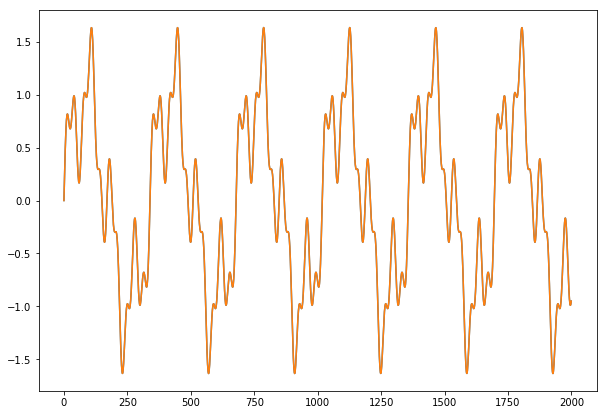

In [464]:
plt.plot(range(len(note2))[:2000], note2.real[:2000])
plt.plot(range(len(note))[0:2000], note[:2000])

$\large{\checkmark}$

---

### Add noise to the FFT

In [474]:
power = np.abs(noteFFT[1:halflen+1])
#noise = 1 * np.random.normal(0,1,halflen)**2
#power = power + noise

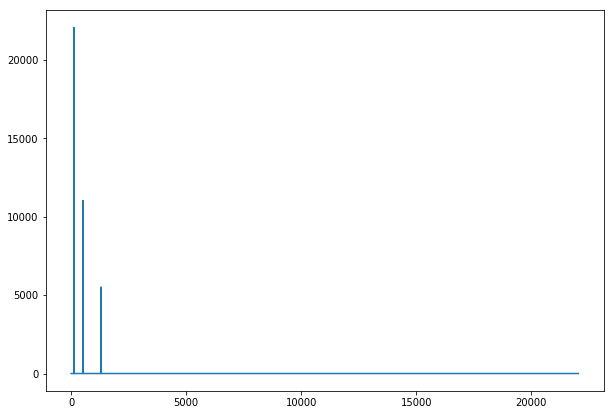

In [477]:
plt.plot(range(len(power)), power)
#plt.yscale('log')

In [478]:
trialFFT = power * 1j
trialFFT = np.insert(trialFFT, 0, 0+0j)
trialFFT = np.append(trialFFT, -trialFFT[-2:0:-1])

trialFFT[0] = 0
trialFFT[halflen-1] = 0 

In [479]:
for i in range(halflen-10, halflen+10):
    print(i,trialFFT[i], trialFFT[4094-i])

22040 4.32147439167e-13j (-0-1.16417212259e-12j)
22041 4.2892773854e-12j (-0-3.97545677569e-12j)
22042 2.78618591028e-12j (-0-8.97142916367e-12j)
22043 5.87094532301e-12j (-0-7.2248493095e-12j)
22044 2.9417226489e-12j (-0-1.09111744314e-11j)
22045 3.61549931431e-12j (-0-2.07955343258e-12j)
22046 5.35736438785e-12j (-0-1.9395479518e-11j)
22047 2.85832463479e-12j (-0-1.31451482103e-11j)
22048 2.87185714835e-12j (-0-1.36570248537e-11j)
22049 0j (-0-1.56581827538e-11j)
22050 2.74218648145e-12j (-0-2.65821043472e-12j)
22051 (-0-2.67338634329e-12j) (-0-1.16139475552e-11j)
22052 (-0-2.87185714835e-12j) (-0-7.45977096005e-12j)
22053 (-0-2.85832463479e-12j) (-0-4.88359001762e-12j)
22054 (-0-5.35736438785e-12j) (-0-9.90748287364e-12j)
22055 (-0-3.61549931431e-12j) (-0-6.19973115602e-12j)
22056 (-0-2.9417226489e-12j) (-0-7.30447839074e-12j)
22057 (-0-5.87094532301e-12j) (-0-3.48741531128e-12j)
22058 (-0-2.78618591028e-12j) (-0-6.03290916753e-12j)
22059 (-0-4.2892773854e-12j) (-0-6.36046745647e-13

In [480]:
note2 = ifft(-trialFFT * 1j)

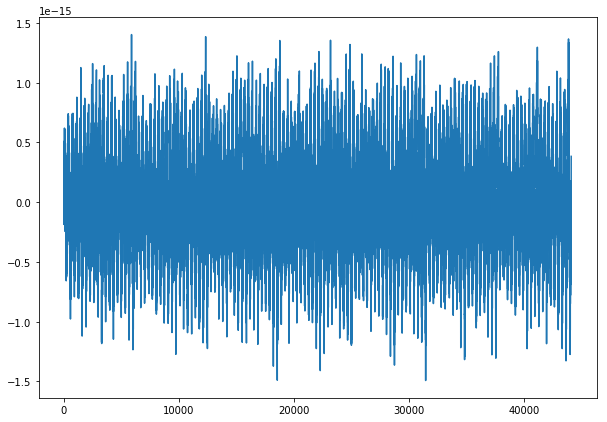

In [481]:
plt.plot(range(len(note2)), note2)

---

### Reproduce a bank sound

In [14]:
srcfile = '../OldFFTBank/flu-a5-ord-mf.nbb'

f = np.fromfile(srcfile, dtype='float32')

In [395]:
len(f)

2048

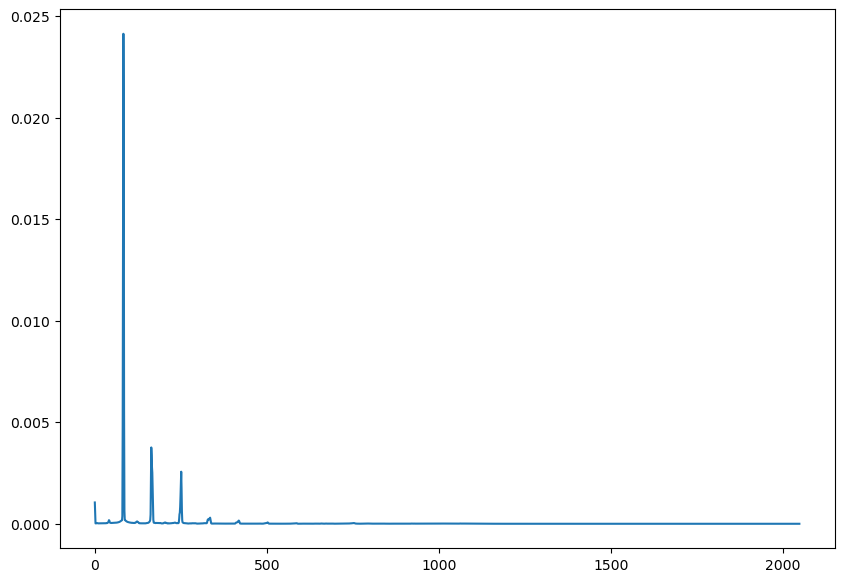

In [15]:
plt.plot(range(len(f)), f, '-')
#plt.yscale('log')
#plt.xlim(80,87)

**Question**: for the Bank power spectra, does the first value represent $f=10.76$ Hz, or $f=0$ Hz?

In [397]:
np.argmax(f)

83

In [398]:
f[80:87]

array([ 0.   ,  0.005,  0.015,  0.024,  0.02 ,  0.006,  0.001], dtype=float32)

In [399]:
10.76*83

893.0799999999999

In [400]:
1323.48 / 329.63

4.015047174104299

An E4 is approximately 330 Hz (329.63).   
The maximum peak in the above power spectrum is at index 123.  
123 * 10.76 Hz = 4.015...  about 4x the E4.

This means that index 123 corresponds to the 123rd freq. bin.

My conclusion: f[0] -> $f_1$, *i.e.* the zero-mode

Hence we *do **NOT** have to add in the zero-mode*.

In [401]:
trialFFT = f

In [402]:
trialFFT[0] = 0

In [403]:
trialFFT = np.append(f, -f[-2:0:-1])

In [404]:
len(trialFFT)

4094

In [405]:
trialFFT = trialFFT * 1j

In [406]:
for i in range(2040, 2060):
    print(i,trialFFT[i], trialFFT[4094-i])

2040 1.27295e-06j (-0-1.27295e-06j)
2041 1.27576e-06j (-0-1.27576e-06j)
2042 1.28561e-06j (-0-1.28561e-06j)
2043 1.27767e-06j (-0-1.27767e-06j)
2044 1.26695e-06j (-0-1.26695e-06j)
2045 1.27302e-06j (-0-1.27302e-06j)
2046 1.28262e-06j (-0-1.28262e-06j)
2047 1.27338e-06j 1.27338e-06j
2048 (-0-1.28262e-06j) 1.28262e-06j
2049 (-0-1.27302e-06j) 1.27302e-06j
2050 (-0-1.26695e-06j) 1.26695e-06j
2051 (-0-1.27767e-06j) 1.27767e-06j
2052 (-0-1.28561e-06j) 1.28561e-06j
2053 (-0-1.27576e-06j) 1.27576e-06j
2054 (-0-1.27295e-06j) 1.27295e-06j
2055 (-0-1.27436e-06j) 1.27436e-06j
2056 (-0-1.28463e-06j) 1.28463e-06j
2057 (-0-1.24479e-06j) 1.24479e-06j
2058 (-0-1.29714e-06j) 1.29714e-06j
2059 (-0-1.2719e-06j) 1.2719e-06j


In [407]:
trialFFT[0] = 0
trialFFT[2047] = 0 

In [408]:
len(trialFFT)

4094

In [409]:
obonote = ifft(-trialFFT*len(trialFFT))

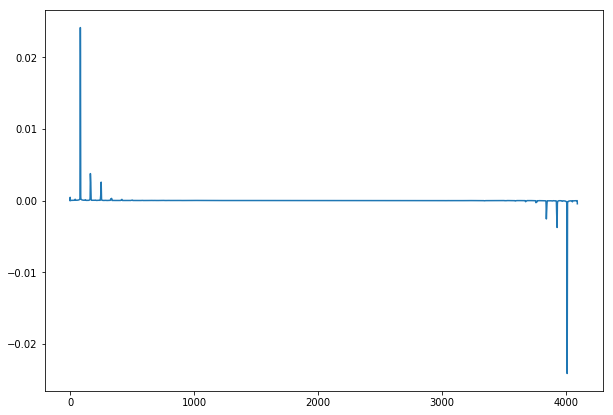

In [410]:
plt.plot(range(len(trialFFT)), trialFFT.imag, '-')
#plt.yscale('log')

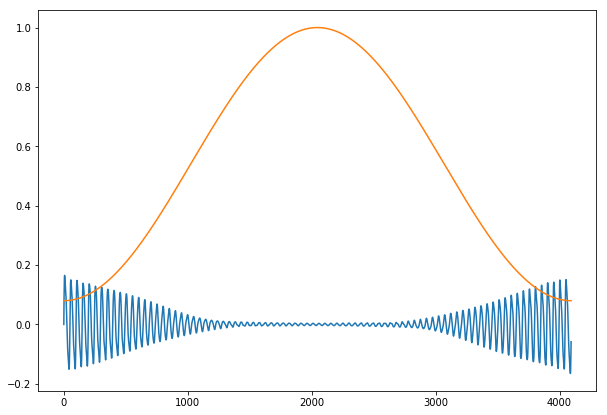

In [496]:
plt.plot(range(len(obonote)), obonote, '-')
#plt.plot(range(len(obonote)), np.hamming(len(obonote)) )

In [483]:
len(obonote)

4094

In [275]:
trialFFT[1]

0.00044775498j

In [276]:
trialFFT[-1]

(-0-0.00044775498j)

In [271]:
trialFFT[0]

0j

---

## Construct the sound "by hand"

In [16]:
f = np.fromfile('../OldFFTBank/pno-c3-ord-mf.nbb', dtype='float32')

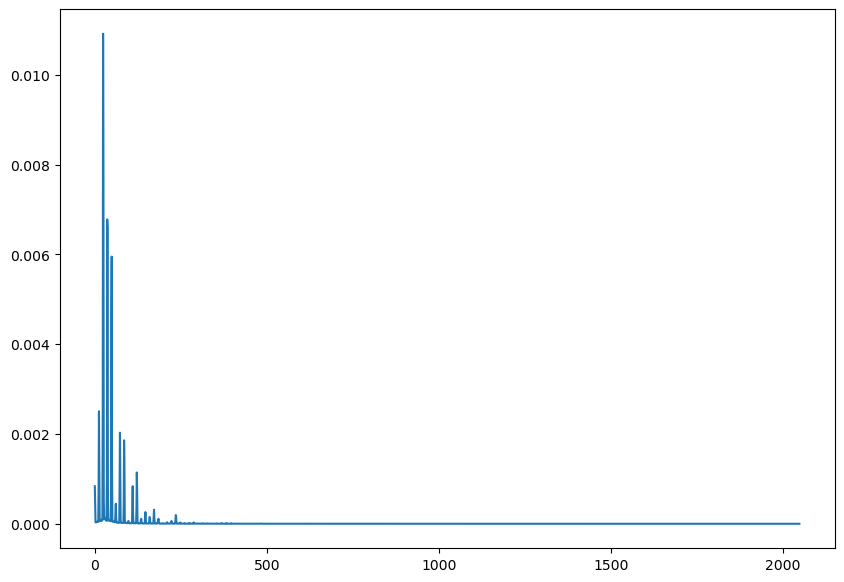

In [17]:
plt.plot(range(len(f)), f, '-')

In [18]:
freqdelta = 44100/4096  # Our played note will be 440 Hz
freqdelta = 10.8
samplerate = 44100  # 44100 samples per second
seconds = 1  # Note duration of 3 seconds

# Generate array with seconds*sample_rate steps, ranging between 0 and seconds
t = np.linspace(0, seconds, seconds * samplerate, False)

# Generate sound
note = np.zeros(seconds*samplerate)
for n in range(15):
    note += f[n] * np.sin( n * freqdelta * t * 2 * np.pi) 

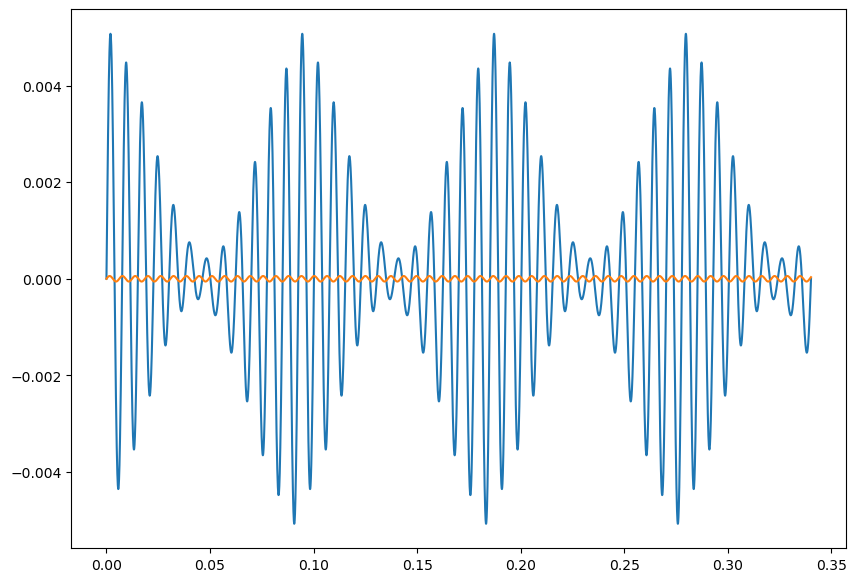

In [19]:
plt.plot(t[:15000], note[:15000])
n = 15
plt.plot(t[:15000], f[n] * np.sin( n * freqdelta * t * 2 * np.pi)[:15000])

In [20]:
# Ensure that highest value is in 16-bit range
audio = note * (2**15 - 1) / np.max(np.abs(note))
# Convert to 16-bit data
audio = audio.astype(np.int16)

In [21]:
# Start playback
play_obj = sa.play_buffer(audio, 1, 2, samplerate)

# Wait for playback to finish before exiting
play_obj.wait_done()

In [22]:
trialFFT[1]

NameError: name 'trialFFT' is not defined

In [30]:
srcfile = '../OldFFTBank/flu-a6-ord-mf.nbb'

powA6 = np.fromfile(srcfile, dtype='float32')

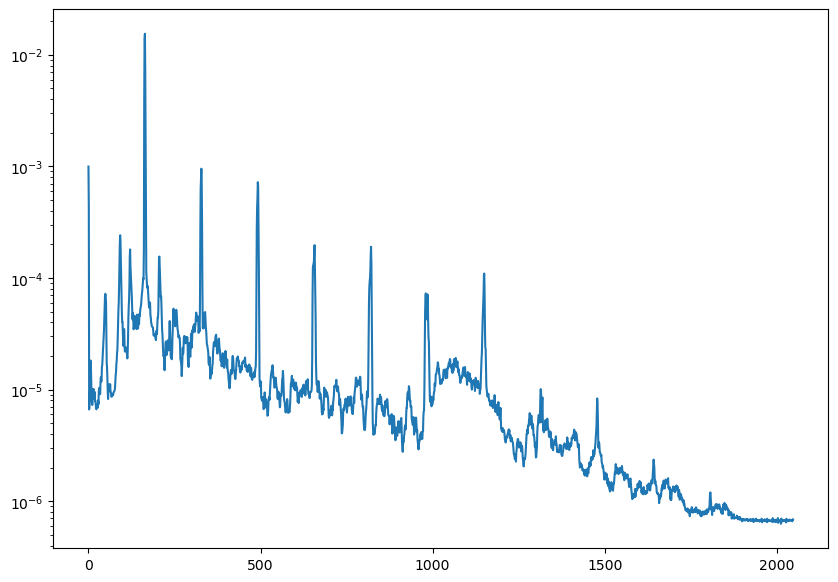

In [32]:
plt.plot(range(len(powA6)), powA6, '-')
plt.yscale('log')

In [29]:
np.argmax(powA6)

41

In [150]:
10.76 * 163

1753.8799999999999